# classical machine-learning experiments

Classical multilabel classifiers are trained on the static 1k datasets and evaluated on the corresponding evaluation 10k datasets.

In [1]:
from pathlib import Path

from skald import combine_runs
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import polars.selectors as cs
import seaborn as sns
import torch
from skimage.transform import warp_polar
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multioutput import ClassifierChain
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from endlesswm.io.datasets import H5WM
from experiments.data import FillNaN
from experiments.visualizations import set_paper_style

set_paper_style()

In [2]:
dataset_labels = ("I", "II", "III", "IV")
dataset_slugs = {"I": "i", "II": "ii", "III": "iii", "IV": "iv"}

static_datasets = {label: Path(f"../../data/generated/static/{slug}-1k.hdf5") for label, slug in dataset_slugs.items()}
evaluation_datasets = {label: Path(f"../../data/generated/evaluation/{slug}-10k.hdf5") for label, slug in dataset_slugs.items()}

train_datasets = tuple(static_datasets)
test_datasets = tuple(evaluation_datasets)
result_schema = {
    "train_dataset": pl.String,
    "features": pl.String,
    "model": pl.String,
    **{f"mAP on eval-{name}": pl.Float64 for name in test_datasets},
}

In [ ]:
model_builders = {
    "OneVsRestClassifier(LogisticRegression)": lambda: make_pipeline(
        StandardScaler(),
        OneVsRestClassifier(LogisticRegression(max_iter=3000, class_weight="balanced")),
    ),
    "ClassifierChain(LogisticRegression)": lambda: make_pipeline(
        StandardScaler(),
        ClassifierChain(
            LogisticRegression(max_iter=3000, class_weight="balanced"),
            order="random",
            random_state=42,
        ),
    ),
    "SVC(kernel='rbf')": lambda: make_pipeline(
        StandardScaler(),
        OneVsRestClassifier(SVC(kernel="rbf", class_weight="balanced")),
    ),
    "HistGradientBoostingClassifier": lambda: OneVsRestClassifier(
        HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=42)
    ),
}

In [ ]:
def summary_stats(image: np.ndarray) -> np.ndarray:
    q = np.quantile(image, [0.0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1.0]).astype(np.float32)
    values = [image.mean(), image.std(), q[5] - q[3], np.abs(image - image.mean()).mean()]
    return np.concatenate([np.asarray(values, dtype=np.float32), q])


def fft_radial(image: np.ndarray, bins: int = 16) -> np.ndarray:
    power = np.abs(np.fft.fftshift(np.fft.fft2(image))) ** 2
    rows, cols = image.shape
    yy, xx = np.indices(image.shape)
    radius = np.hypot(yy - (rows - 1) / 2, xx - (cols - 1) / 2)
    edges = np.linspace(0, radius.max(), bins + 1)
    features = np.array(
        [power[(radius >= left) & (radius < right)].mean() for left, right in zip(edges[:-1], edges[1:])],
        dtype=np.float32,
    )
    features = np.nan_to_num(np.log1p(features), nan=0.0)
    return features / features.sum() if features.sum() > 0 else features


def polar_projection(image: np.ndarray, rows: int = 16, cols: int = 16) -> np.ndarray:
    polar = warp_polar(image, radius=None, output_shape=(rows, cols)).astype(np.float32)
    radial = polar.mean(axis=1)
    angular = polar.mean(axis=0)
    radial = (radial - radial.mean()) / (radial.std() + 1e-6)
    angular = (angular - angular.mean()) / (angular.std() + 1e-6)
    return np.concatenate([radial, angular]).astype(np.float32)


feature_builders = {
    "summary_stats": [summary_stats],
    "fft_radial": [fft_radial],
    "polar_projection": [polar_projection],
    "all combined": [summary_stats, fft_radial, polar_projection],
}

In [ ]:
features = {}
y = {}

for split_name, paths in [("train", static_datasets), ("eval", evaluation_datasets)]:
    for dataset_name, path in paths.items():
        data = H5WM(str(path), transform={"sample": FillNaN()})

        print(f"extract features for {split_name}/{dataset_name}")
        images = []
        labels = []
        for index in range(len(data)):
            sample, label = data[index]
            image = sample.detach().cpu().numpy() if isinstance(sample, torch.Tensor) else np.asarray(sample)
            if image.ndim == 3 and image.shape[0] == 1:
                image = image[0]
            images.append(np.nan_to_num(image, nan=0.0).astype(np.float32, copy=False))
            labels.append(label.detach().cpu().numpy().astype(np.int32))
        y[split_name, dataset_name] = np.stack(labels)
        for feature_name, builders in feature_builders.items():
            features[split_name, dataset_name, feature_name] = np.stack(
                [np.concatenate([build(image) for build in builders]) for image in images]
            )
        print(f"extracted features for {split_name}/{dataset_name}")

rows = []
grid = [
    (train_name, feature_name, model_name)
    for train_name in train_datasets
    for feature_name in feature_builders
    for model_name in model_builders
]
for train_name, feature_name, model_name in grid:
    model = model_builders[model_name]()
    model.fit(features["train", train_name, feature_name], y["train", train_name])
    print(f"fit {model_name} on {train_name} with {feature_name}")

    row = {"train_dataset": train_name, "features": feature_name, "model": model_name}
    for test_name in test_datasets:
        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(features["eval", test_name, feature_name])
            if isinstance(y_score, list):
                y_score = np.column_stack([scores[:, 1] for scores in y_score])
        elif hasattr(model, "decision_function"):
            y_score = model.decision_function(features["eval", test_name, feature_name])
        else:
            y_score = model.predict(features["eval", test_name, feature_name])
        map_score = float(average_precision_score(y["eval", test_name], np.asarray(y_score), average="macro"))
        row[f"mAP on eval-{test_name}"] = map_score
        print(f"score {model_name} | train={train_name} | test={test_name} | {feature_name} | mAP={map_score:.4f}")
    rows.append(row)

experiment_results = pl.DataFrame(rows, schema=result_schema).sort(["train_dataset", "features", "model"])

experiment_results

extract features for train/I
extracted features for train/I
extract features for train/II
extracted features for train/II
extract features for train/III
extracted features for train/III
extract features for train/IV
extracted features for train/IV
extract features for eval/I
extracted features for eval/I
extract features for eval/II
extracted features for eval/II
extract features for eval/III
extracted features for eval/III
extract features for eval/IV
extracted features for eval/IV
fit OneVsRestClassifier(LogisticRegression) on I with summary_stats
score OneVsRestClassifier(LogisticRegression) | train=I | test=I | summary_stats | mAP=0.4965
score OneVsRestClassifier(LogisticRegression) | train=I | test=II | summary_stats | mAP=0.4995
score OneVsRestClassifier(LogisticRegression) | train=I | test=III | summary_stats | mAP=0.3952
score OneVsRestClassifier(LogisticRegression) | train=I | test=IV | summary_stats | mAP=0.3607
fit ClassifierChain(LogisticRegression) on I with summary_stats


train_dataset,features,model,mAP on eval-I,mAP on eval-II,mAP on eval-III,mAP on eval-IV
str,str,str,f64,f64,f64,f64
"""I""","""all combined""","""ClassifierChain(LogisticRegres…",0.846245,0.819977,0.422163,0.39313
"""I""","""all combined""","""HistGradientBoostingClassifier""",0.876929,0.705896,0.428712,0.396979
"""I""","""all combined""","""OneVsRestClassifier(LogisticRe…",0.82392,0.79736,0.422995,0.397074
"""I""","""all combined""","""SVC(kernel='rbf')""",0.866658,0.706489,0.44628,0.431025
"""I""","""fft_radial""","""ClassifierChain(LogisticRegres…",0.59756,0.561095,0.42541,0.389744
…,…,…,…,…,…,…
"""IV""","""polar_projection""","""SVC(kernel='rbf')""",0.585784,0.592612,0.594834,0.558571
"""IV""","""summary_stats""","""ClassifierChain(LogisticRegres…",0.268769,0.422488,0.436856,0.409109
"""IV""","""summary_stats""","""HistGradientBoostingClassifier""",0.342877,0.480104,0.479348,0.436897


In [ ]:
ml_results = (
    experiment_results.rename({"train_dataset": "train"})
    .unpivot(
        index=["train", "features", "model"],
        on=["mAP on eval-I", "mAP on eval-II", "mAP on eval-III", "mAP on eval-IV"],
        variable_name="test",
        value_name="mAP",
    )
    .with_columns(pl.col("test").str.strip_prefix("mAP on eval-"))
    .drop_nulls("mAP")
)
ml_results

train,features,model,test,mAP
str,str,str,str,f64
"""I""","""all combined""","""ClassifierChain(LogisticRegres…","""I""",0.846245
"""I""","""all combined""","""HistGradientBoostingClassifier""","""I""",0.876929
"""I""","""all combined""","""OneVsRestClassifier(LogisticRe…","""I""",0.82392
"""I""","""all combined""","""SVC(kernel='rbf')""","""I""",0.866658
"""I""","""fft_radial""","""ClassifierChain(LogisticRegres…","""I""",0.59756
…,…,…,…,…
"""IV""","""polar_projection""","""SVC(kernel='rbf')""","""IV""",0.558571
"""IV""","""summary_stats""","""ClassifierChain(LogisticRegres…","""IV""",0.409109
"""IV""","""summary_stats""","""HistGradientBoostingClassifier""","""IV""",0.436897


## raw-input ResNet18 rows

Raw-input ResNet18 values are loaded from the static-complexity report at data fraction 0.01.

In [ ]:
resnet18_static_metrics = (
    combine_runs(
        Path(r"W:\EndlessWM\experiments\reports\static_complexity"),
        include_params=["data.name", "data.stream.data_fraction", "seed"],
    )
    .rename({"data.name": "dataset"})
    .filter(
        name="mAP",
        pattern="*",
        task=0,
    )
    .with_columns(
        pl.col("epoch").cast(pl.Int64),
        pl.col("data.stream.data_fraction").cast(pl.Float64),
    )
    .filter(
        pl.col("epoch").is_null(),
        pl.col("data.stream.data_fraction") == 0.01,
    )
    .sort("dataset")
)

resnet18_static_metrics

2026-07-03 09:16:13.545 | INFO     | skald:combine_runs:463 - 🔎 found 144 skald runs in W:\EndlessWM\experiments\reports\static_complexity.


Output()

name,value,stream,step,epoch,task,pattern,dataset,data.stream.data_fraction,seed
str,f64,str,i64,i64,i64,str,str,f64,i32
"""mAP""",0.9573,"""i""",null,null,0,"""*""","""I""",0.01,42
"""mAP""",0.8958,"""ii""",null,null,0,"""*""","""I""",0.01,42
"""mAP""",0.5695,"""iii""",null,null,0,"""*""","""I""",0.01,42
"""mAP""",0.5267,"""iv""",null,null,0,"""*""","""I""",0.01,42
"""mAP""",0.9593,"""present""",null,null,0,"""*""","""I""",0.01,42
…,…,…,…,…,…,…,…,…,…
"""mAP""",0.9165,"""ii""",null,null,0,"""*""","""IV""",0.01,44
"""mAP""",0.8963,"""iii""",null,null,0,"""*""","""IV""",0.01,44
"""mAP""",0.863,"""iv""",null,null,0,"""*""","""IV""",0.01,44


In [ ]:
resnet18_results = (
    resnet18_static_metrics.filter(pl.col("epoch").is_null())
    .with_columns(pl.col("stream").str.to_uppercase())
    .filter(pl.col("stream").is_in(["I", "II", "III", "IV"]))
    .rename(
        {
            "dataset": "train",
            "stream": "test",
            "value": "mAP",
        }
    )
    .drop(
        ["name", "step", "epoch", "data.stream.data_fraction"],
        strict=False,
    )
    .group_by(["train", "test"])
    .agg(pl.col("mAP").mean())
    .sort(["train", "test"])
    .with_columns(
        pl.lit("raw input").alias("features"),
        pl.lit("ResNet18").alias("model"),
    )
)
resnet18_results

train,test,mAP,features,model
str,str,f64,str,str
"""I""","""I""",0.958033,"""raw input""","""ResNet18"""
"""I""","""II""",0.889633,"""raw input""","""ResNet18"""
"""I""","""III""",0.558033,"""raw input""","""ResNet18"""
"""I""","""IV""",0.518033,"""raw input""","""ResNet18"""
"""II""","""I""",0.8914,"""raw input""","""ResNet18"""
…,…,…,…,…
"""III""","""IV""",0.839533,"""raw input""","""ResNet18"""
"""IV""","""I""",0.866933,"""raw input""","""ResNet18"""
"""IV""","""II""",0.912633,"""raw input""","""ResNet18"""


In [ ]:
results = pl.concat(
    [ml_results, resnet18_results.select(ml_results.columns)],
    how="vertical_relaxed",
)
results
results.write_csv("../../reports/ml/results.csv")

In [2]:
results = pl.read_csv("../../reports/ml/results.csv")

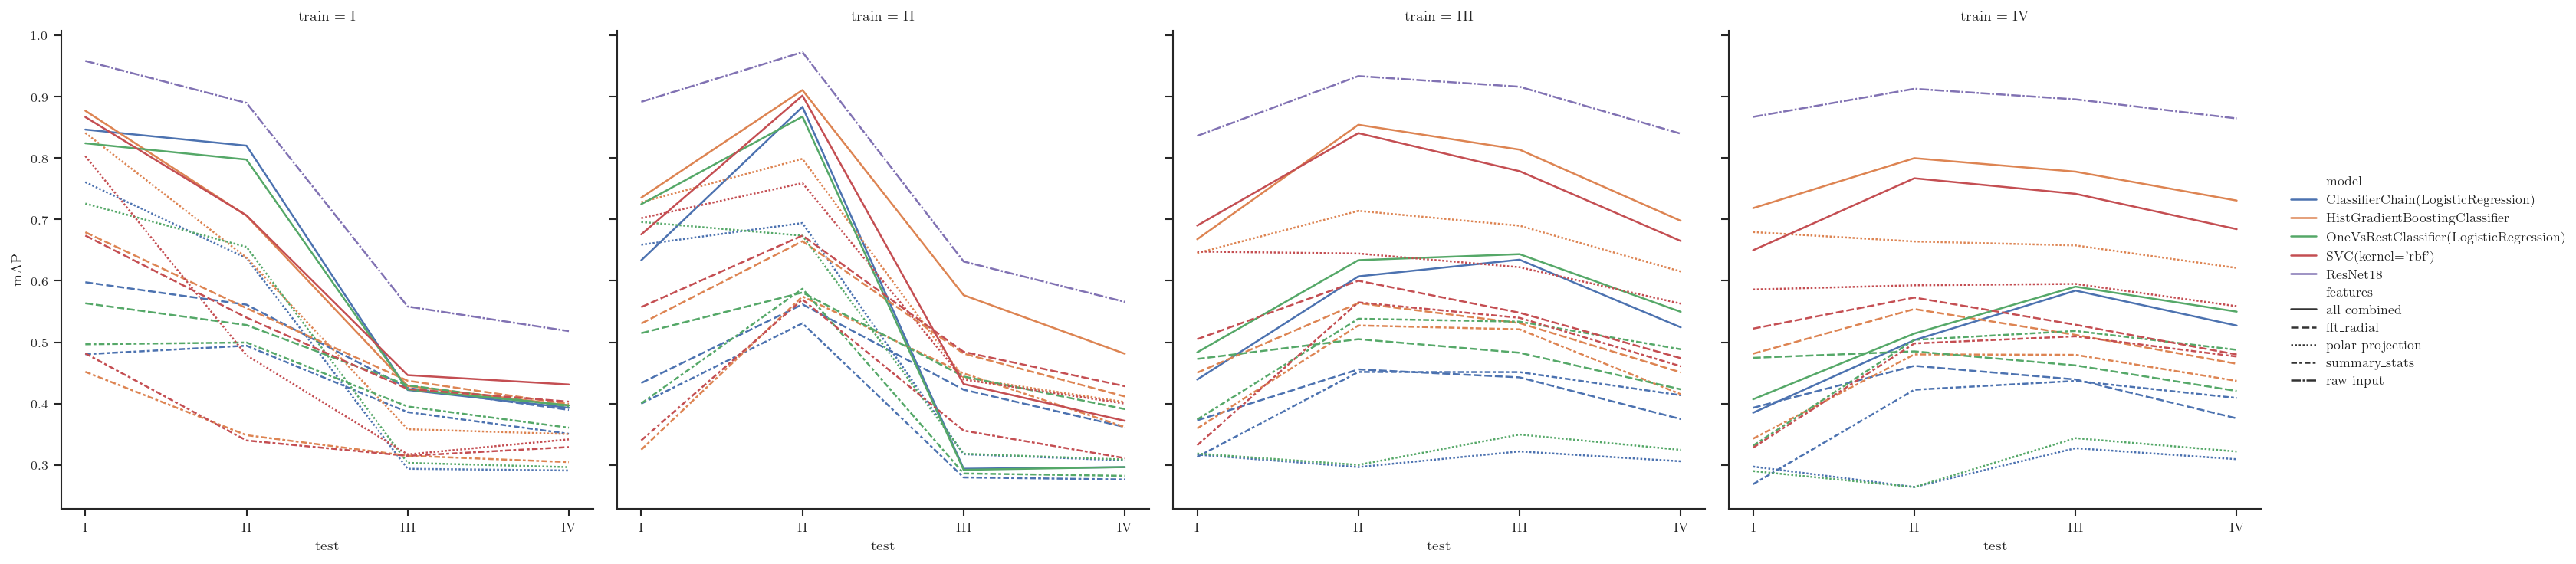

In [4]:
sns.relplot(
    data=results,
    x="test",
    y="mAP",
    hue="model",
    style="features",
    col="train",
    kind="line",
)

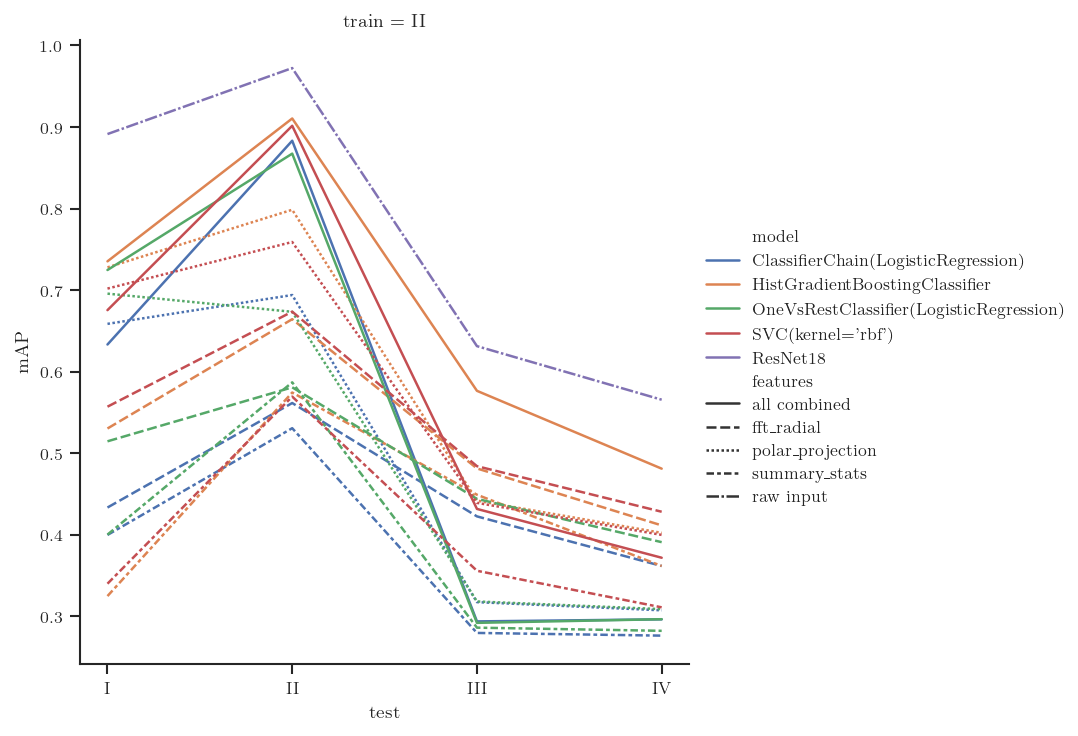

In [ ]:
sns.relplot(
    data=results.filter(train="II"),
    x="test",
    y="mAP",
    hue="model",
    style="features",
    col="train",
    kind="line",
)

NameError: name 'dataset_order' is not defined

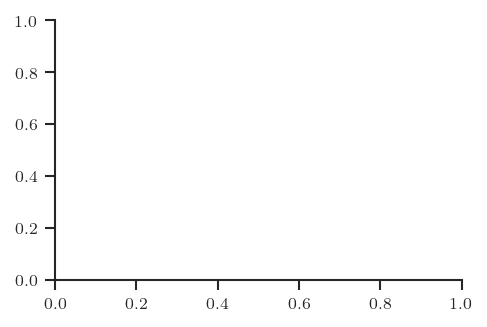

In [5]:
set_paper_style()

_plot_df = results.filter(train="II")

_fig, _ax = plt.subplots(figsize=(3.5, 2.25))

sns.lineplot(
    data=_plot_df,
    x="№ samples",
    y="value",
    hue="dataset",
    hue_order=dataset_order,
    ax=_ax,
)

_ax.set_xlabel("test distribution")
_ax.set_ylabel("mAP")

sns.move_legend(
    _ax,
    "lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=len(dataset_order),
    title=None,
    frameon=True,
    borderaxespad=1.0,
    borderpad=0.25,
    handlelength=1.0,
    handletextpad=0.5,
    columnspacing=1.0,
    labelspacing=0.2,
)

_fig.tight_layout()

_fig

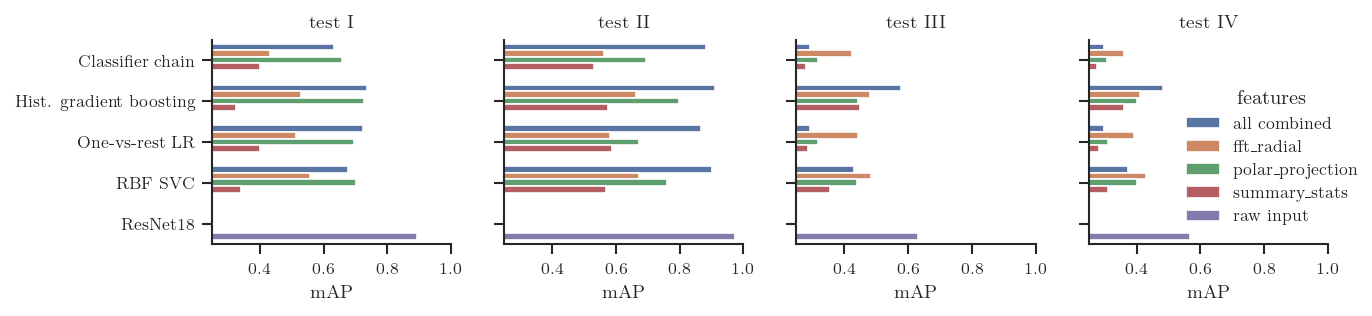

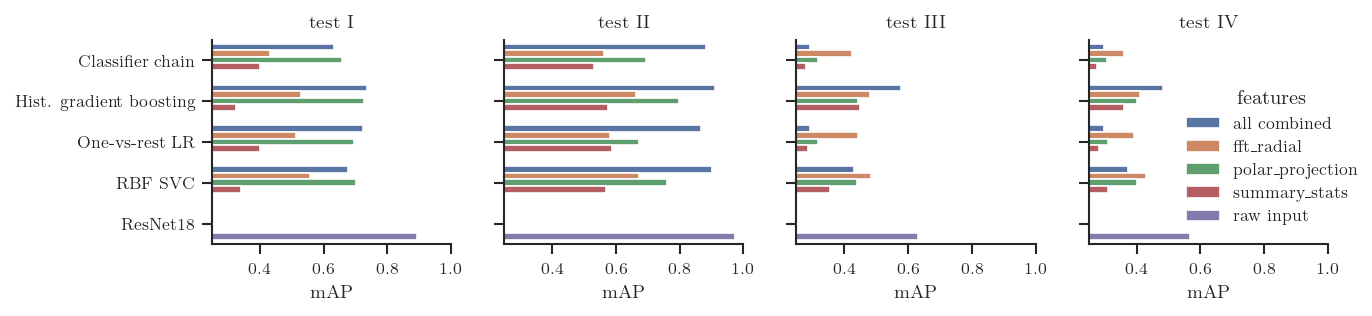

In [6]:
set_paper_style()

_dataset_order = ["I", "II", "III", "IV"]

_plot_df = (
    results.filter(pl.col("train") == "II")
    .with_columns(
        pl.when(pl.col("model") == "ClassifierChain(LogisticRegression)")
        .then(pl.lit("Classifier chain"))
        .when(pl.col("model") == "OneVsRestClassifier(LogisticRegression)")
        .then(pl.lit("One-vs-rest LR"))
        .when(pl.col("model") == "HistGradientBoostingClassifier")
        .then(pl.lit("Hist. gradient boosting"))
        .when(pl.col("model") == "SVC(kernel='rbf')")
        .then(pl.lit("RBF SVC"))
        .otherwise(pl.col("model"))
        .alias("model_label")
    )
    .to_pandas()
)

_grid = sns.catplot(
    data=_plot_df,
    y="model_label",
    x="mAP",
    hue="features",
    col="test",
    col_order=_dataset_order,
    kind="bar",
    height=2.2,
    aspect=0.9,
    legend=True,
)

_grid.set_axis_labels("mAP", "")
_grid.set_titles("test {col_name}")

for _ax in _grid.axes.flat:
    _ax.set_xlim(0.25, 1.0)

_grid.fig.tight_layout()
_grid.fig

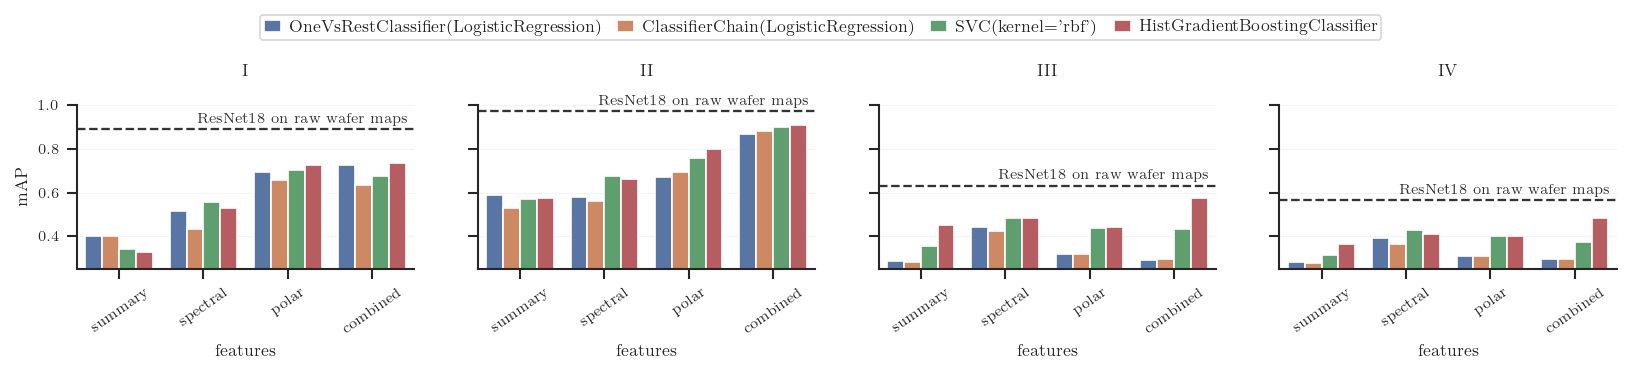

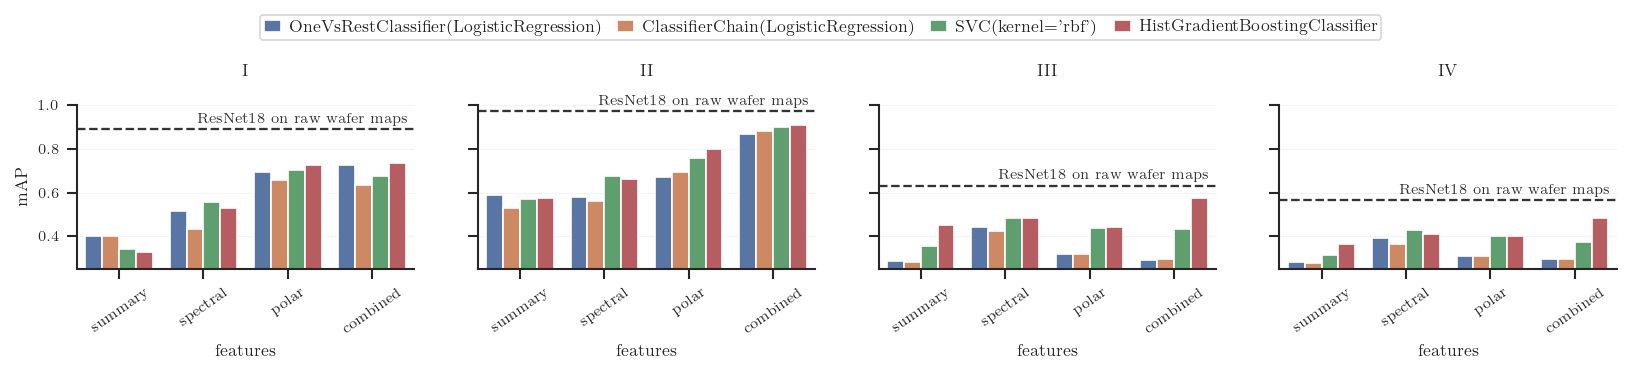

In [7]:
set_paper_style()
plt.rcParams.update(
    {
        "axes.labelsize": 8,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "lines.linewidth": 0.9,
        "lines.markersize": 3,
    },
)

_dataset_order = ["I", "II", "III", "IV"]
_feature_order = ["summary_stats", "fft_radial", "polar_projection", "all combined"]
_model_order = [
    "OneVsRestClassifier(LogisticRegression)",
    "ClassifierChain(LogisticRegression)",
    "SVC(kernel='rbf')",
    "HistGradientBoostingClassifier",
]
_feature_labels = {
    "summary_stats": "summary",
    "fft_radial": "spectral",
    "polar_projection": "polar",
    "all combined": "combined",
}

_plot_df = (
    results.filter(
        pl.col("train") == "II",
        pl.col("model") != "ResNet18",
    )
    .with_columns(
        pl.col("features").replace(_feature_labels).alias("feature_label"),
    )
    .to_pandas()
)

_resnet_df = results.filter(
    pl.col("train") == "II",
    pl.col("model") == "ResNet18",
).select(["test", "mAP"])

_grid = sns.catplot(
    data=_plot_df,
    x="feature_label",
    y="mAP",
    hue="model",
    hue_order=_model_order,
    col="test",
    col_order=_dataset_order,
    order=[_feature_labels[name] for name in _feature_order],
    kind="bar",
    height=2.25,
    aspect=0.95,
    legend=True,
)

_grid.set_axis_labels("features", "mAP")
_grid.set_titles("{col_name}", pad=14)

sns.move_legend(
    _grid,
    "lower center",
    bbox_to_anchor=(0.5, 0.96),
    ncol=4,
    title=None,
    frameon=True,
    borderaxespad=1.0,
    borderpad=0.25,
    handlelength=1.0,
    handletextpad=0.5,
    columnspacing=1.0,
    labelspacing=0.2,
)

for _ax, _test in zip(_grid.axes.flat, _dataset_order):
    _resnet_map = _resnet_df.filter(pl.col("test") == _test).select("mAP").item()

    _ax.axhline(
        _resnet_map,
        color="0.2",
        linestyle="--",
        linewidth=1.1,
        zorder=0,
    )
    _ax.text(
        0.98,
        _resnet_map + 0.015,
        "ResNet18 on raw wafer maps",
        transform=_ax.get_yaxis_transform(),
        ha="right",
        va="bottom",
        fontsize=7,
        color="0.2",
    )
    _ax.set_ylim(0.25, 1.0)
    _ax.grid(True, axis="y", alpha=0.22, linewidth=0.5)
    _ax.tick_params(axis="x", rotation=35)

_grid.fig.subplots_adjust(top=0.78)

_grid.fig.tight_layout()

_output_dir = Path("../../reports/ml")
_output_dir.mkdir(parents=True, exist_ok=True)

_grid.fig.savefig(_output_dir / "ml_experiments.png", bbox_inches="tight", dpi=300)
_grid.fig.savefig(_output_dir / "ml_experiments.pdf", bbox_inches="tight")

_grid.fig

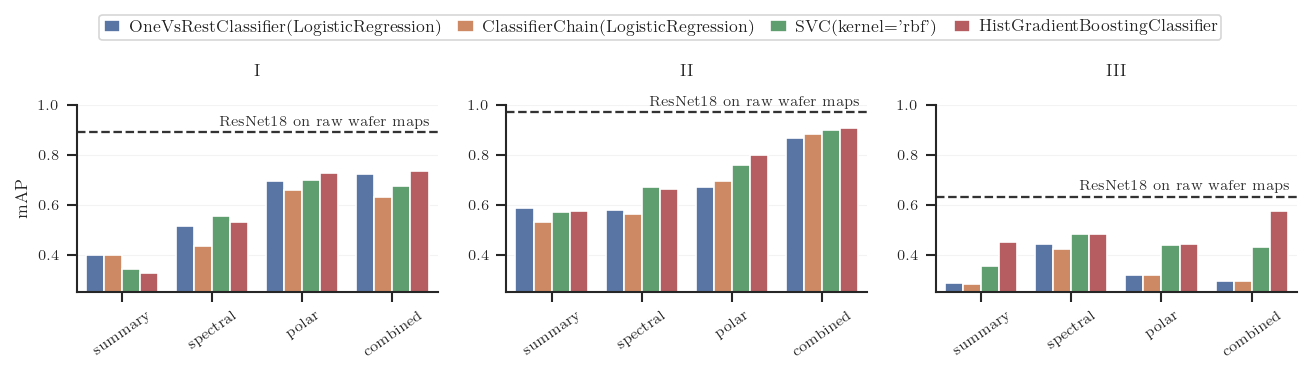

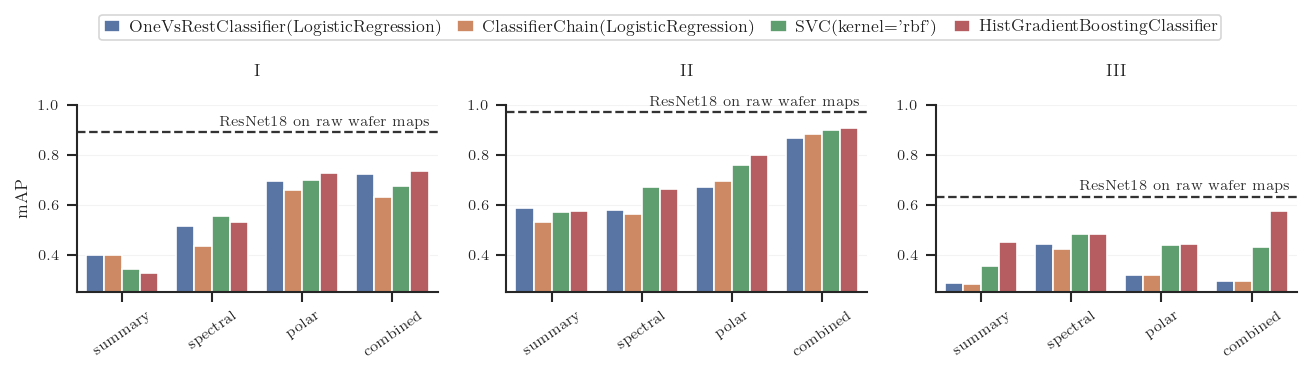

In [ ]:
set_paper_style()
plt.rcParams.update(
    {
        "axes.labelsize": 8,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "lines.linewidth": 0.9,
        "lines.markersize": 3,
    },
)

# Exclude dataset IV from this figure
_dataset_order = ["I", "II", "III"]
_dataset_labels = {"I": "EWM-I", "II": "EWM-II", "III": "EWM-III"}
_feature_order = ["summary_stats", "fft_radial", "polar_projection", "all combined"]
_model_order = [
    "OneVsRestClassifier(LogisticRegression)",
    "ClassifierChain(LogisticRegression)",
    "SVC(kernel='rbf')",
    "HistGradientBoostingClassifier",
]
_feature_labels = {
    "summary_stats": "summary",
    "fft_radial": "spectral",
    "polar_projection": "polar",
    "all combined": "combined",
}

_plot_df = (
    results.filter(
        pl.col("train") == "II",
        pl.col("model") != "ResNet18",
        pl.col("test").is_in(_dataset_order),
    )
    .with_columns(
        pl.col("features").replace(_feature_labels).alias("feature_label"),
        pl.col("test").replace(_dataset_labels).alias("test_label"),
    )
    .to_pandas()
)

_resnet_df = results.filter(
    pl.col("train") == "II",
    pl.col("model") == "ResNet18",
    pl.col("test").is_in(_dataset_order),
).select(["test", "mAP"])

_grid = sns.catplot(
    data=_plot_df,
    x="feature_label",
    y="mAP",
    hue="model",
    hue_order=_model_order,
    col="test_label",
    col_order=[_dataset_labels[_dataset] for _dataset in _dataset_order],
    order=[_feature_labels[name] for name in _feature_order],
    kind="bar",
    height=2.25,
    aspect=0.95,
    legend=True,
)

# Remove "features" axis label text
_grid.set_axis_labels("", "mAP")
_grid.set_titles("{col_name}", pad=14)

sns.move_legend(
    _grid,
    "lower center",
    bbox_to_anchor=(0.5, 0.96),
    ncol=4,
    title=None,
    frameon=True,
    borderaxespad=1.0,
    borderpad=0.25,
    handlelength=1.0,
    handletextpad=0.5,
    columnspacing=1.0,
    labelspacing=0.2,
    fontsize=8,  # slightly larger legend text
)

for _idx, (_ax, _test) in enumerate(zip(_grid.axes.flat, _dataset_order, strict=True)):
    _resnet_map = _resnet_df.filter(pl.col("test") == _test).select("mAP").item()

    _ax.axhline(
        _resnet_map,
        color="0.2",
        linestyle="--",
        linewidth=1.1,
        zorder=0,
    )
    _ax.text(
        0.98,
        _resnet_map + 0.015,
        "ResNet18 on raw wafer maps",
        transform=_ax.get_yaxis_transform(),
        ha="right",
        va="bottom",
        fontsize=7,
        color="0.2",
    )
    _ax.set_ylim(0.25, 1.0)
    _ax.grid(visible=True, axis="y", alpha=0.22, linewidth=0.5)
    _ax.tick_params(axis="x", rotation=35, labelbottom=True)

    # Add y-tick labels to 2nd and 3rd plots (no extra axis labels)
    if _idx in (1, 2):
        _ax.tick_params(axis="y", labelleft=True)

_grid.figure.subplots_adjust(top=0.78)
_grid.figure.tight_layout()

_output_dir = Path("../../reports/ml")
_output_dir.mkdir(parents=True, exist_ok=True)

_grid.figure.savefig(_output_dir / "ml_experiments_reduced.png", bbox_inches="tight", dpi=300)
_grid.figure.savefig(_output_dir / "ml_experiments_reduced.pdf", bbox_inches="tight")

_grid.figure

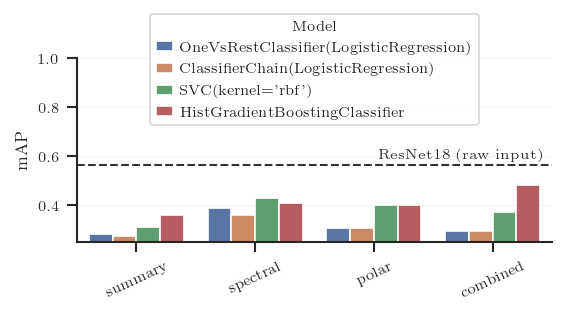

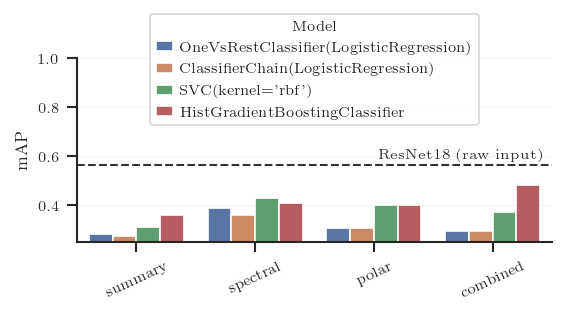

In [15]:
set_paper_style()
plt.rcParams.update(
    {
        "axes.labelsize": 8,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "lines.linewidth": 0.9,
        "lines.markersize": 3,
        "legend.fontsize": 7,
    },
)

_feature_order = ["summary_stats", "fft_radial", "polar_projection", "all combined"]
_model_order = [
    "OneVsRestClassifier(LogisticRegression)",
    "ClassifierChain(LogisticRegression)",
    "SVC(kernel='rbf')",
    "HistGradientBoostingClassifier",
]
_feature_labels = {
    "summary_stats": "summary",
    "fft_radial": "spectral",
    "polar_projection": "polar",
    "all combined": "combined",
}

_plot_df = (
    results.filter(
        pl.col("train") == "II",
        pl.col("test") == "IV",
        pl.col("model") != "ResNet18",
    )
    .with_columns(pl.col("features").replace(_feature_labels).alias("feature_label"))
    .to_pandas()
)

_resnet_map = (
    results.filter(
        pl.col("train") == "II",
        pl.col("test") == "IV",
        pl.col("model") == "ResNet18",
    )
    .select("mAP")
    .item()
)

# Keep original (non-stretched) aspect ratio
fig, ax = plt.subplots(figsize=(3.6, 2.45))

sns.barplot(
    data=_plot_df,
    x="feature_label",
    y="mAP",
    hue="model",
    hue_order=_model_order,
    order=[_feature_labels[name] for name in _feature_order],
    ax=ax,
)

ax.axhline(_resnet_map, color="0.2", linestyle="--", linewidth=1.0, zorder=0)
ax.text(
    0.98,
    _resnet_map + 0.012,
    "ResNet18 (raw input)",
    transform=ax.get_yaxis_transform(),
    ha="right",
    va="bottom",
    fontsize=6.8,
    color="0.2",
)

# Remove title to free vertical space
ax.set_title("")
ax.set_xlabel("")
ax.set_ylabel("mAP")
ax.set_ylim(0.25, 1.0)
ax.grid(visible=True, axis="y", alpha=0.22, linewidth=0.5)
ax.tick_params(axis="x", rotation=25)

_handles, _labels = ax.get_legend_handles_labels()
if ax.legend_ is not None:
    ax.legend_.remove()

# One legend item per row, above plot
ax.legend(
    _handles,
    _labels,
    title="Model",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.6),
    ncol=1,
    frameon=True,
    fontsize=7,
    title_fontsize=7,
    columnspacing=0.9,
    handlelength=1.2,
    handletextpad=0.5,
)

fig.subplots_adjust(left=0.1, right=0.98, bottom=0.22, top=0.72)

_output_dir = Path("../../reports/ml")
_output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(_output_dir / "ml_experiments_iv_only.png", bbox_inches="tight", dpi=300)
fig.savefig(_output_dir / "ml_experiments_iv_only.pdf", bbox_inches="tight")

fig